# Prova 2
Data: 21.10.2026

- Michelini Tommaso
- Marsilio Mariafrancesca
- Manzini Martina

In [60]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, minimize
from scipy.stats import chi2 


ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"


# Attivita 1

True
True
True
Numero di punti: 161
Intervallo di x: [-5.0, 5.0] mm
Intervallo di y: [10.0, 428.0]
Intervallo di sigma_y: [3.162, 20.688]


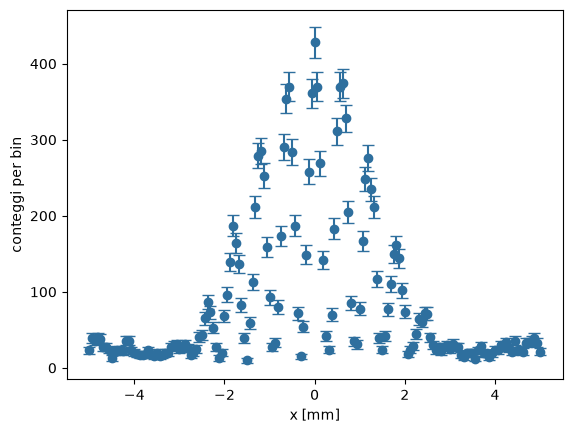

In [61]:
dati = np.genfromtxt(
    "dati_fit_interferenza.csv",
    delimiter=",",
    names=True
    )

x = dati["x"]
y = dati["y"]
sigma_y = dati["sigma_y"]

print(len(x) == len(y) == len(sigma_y))
print(np.isfinite(x).all() and np.isfinite(y).all() and np.isfinite(sigma_y).all())
print((sigma_y > 0).all())
# posizioni ordinate

print(f"Numero di punti: {len(x)}")
print(f"Intervallo di x: [{x.min()}, {x.max()}] mm")
print(f"Intervallo di y: [{y.min()}, {y.max()}]")
print(f"Intervallo di sigma_y: [{sigma_y.min():.3f}, {sigma_y.max():.3f}]")
plt.plot()
plt.errorbar(x, y, yerr=sigma_y, fmt="o", capsize=4, color=AZZURRO)
plt.xlabel("x [mm]")
plt.ylabel("conteggi per bin")
 
plt.show()

# Attività 2

In [62]:

B0 = np.median(y[np.abs(x) > 4.0])
I0 = y.max() - B0
alpha0 = 0.90
delta0 = 5.20


lower = [0.0,0.0,0.10,1.0]
upper = [np.inf, np.inf, 3.0, 12.0]

p0 = [B0, I0, alpha0, delta0]
par_names = ["B0", "I0", "alpha0", "delta0"]

print("Parametri iniziali e bounds:")
for name, value, inf, sup in zip(
    par_names, p0, lower, upper
):
    print(f"{name} = {value}, bounds = [{inf}, {sup}]")




Parametri iniziali e bounds:
B0 = 27.0, bounds = [0.0, inf]
I0 = 401.0, bounds = [0.0, inf]
alpha0 = 0.9, bounds = [0.1, 3.0]
delta0 = 5.2, bounds = [1.0, 12.0]


# Attività 3

La matrice di correlazione mostra che la correlazione più forte tra due parametri distinti è quella tra I0 e alpha, con coefficiente rho = 0.44. Si tratta di una correlazione positiva moderata: i due parametri tendono a variare nella stessa direzione.

Parametri con incertezze
B0 = 18.66 +- 0.49 u.a
I0 = 396.42 +- 5.00 u.a
alpha0 = 0.90 +- 0.01 mm^-1
delta0 = 5.21 +- 0.01 mm^-1


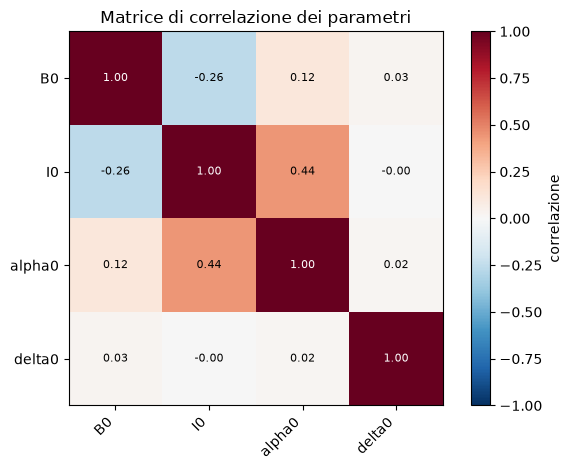

In [63]:
def model(x, B, I0, alpha, delta):
    E = np.sinc(alpha*x/np.pi)**2
    C = np.cos(delta*x)**2
    return B + I0*E*C  

popt, pcov = curve_fit(
    model, x, y,
    p0=p0,
    sigma=sigma_y,
    absolute_sigma=True,
    bounds=(lower,upper),
    maxfev=100000
)

par_errs = np.sqrt(np.diag(pcov))
scale = np.outer(par_errs, par_errs)
corr = pcov / scale
units = ["u.a", "u.a", "mm^-1", "mm^-1"]

print("Parametri con incertezze")
for name, value, error, unit in zip(
    par_names, popt, par_errs, units
):
    print(f"{name} = {value:.2f} +- {error:.2f} {unit}")

fig, ax = plt.subplots()
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(par_names)), par_names, rotation=45, ha="right")
ax.set_yticks(range(len(par_names)), par_names)
ax.set_title("Matrice di correlazione dei parametri")

for row in range(len(par_names)):
    for column in range(len(par_names)):
        color = "white" if abs(corr[row, column]) > 0.55 else "black"
        ax.text(column, row, f"{corr[row, column]:.2f}",
                ha="center", va="center", fontsize=8, color=color)

fig.colorbar(image, ax=ax, label="correlazione")
plt.tight_layout()
plt.show()


# Attività 4

chi2 osservato = 143.312
gradi di libertà = 157
chi2_ridotto = 0.912814
p_value = 0.775840941882729


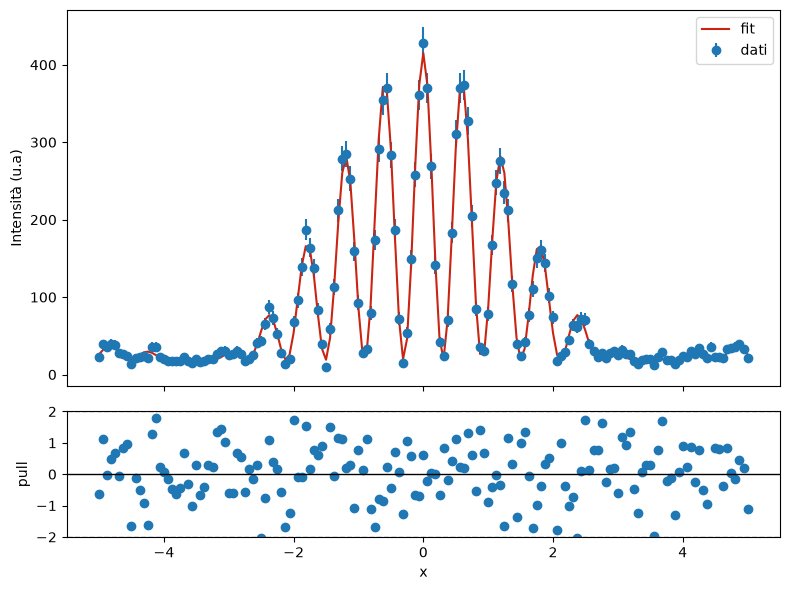

In [71]:
y_fit = model(x, *popt)
residui = y - y_fit
pulls = residui / sigma_y
chi2_obs = np.sum(pull**2)
ndf = len(x) - len(popt)
chi2_rid = chi2_obs / ndf

p_value = chi2.sf(chi2_obs, ndf)


print(f"chi2 osservato = {chi2_obs:.3f}")
print(f"gradi di libertà = {ndf}")
print(f"chi2_ridotto = {chi2_rid:3f}")
print(f"p_value = {p_value}")

fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

ax_top.errorbar(x, y, yerr=sigma_y, fmt="o", label="dati")
ax_top.plot(x, y_fit, color=ROSSO, label="fit")
ax_top.legend()
ax_top.set_ylabel("Intensità (u.a)")

ax_bottom.axhline(0, color="black", lw=1)
ax_bottom.axhline(2, color="gray", ls="--", lw=1)
ax_bottom.axhline(-2, color="gray", ls="--", lw=1)
ax_bottom.scatter(x, pulls, color="tab:blue")
ax_bottom.set(xlabel="x", ylabel="pull", ylim=(-2.0, 2.0))

plt.tight_layout()
plt.show()
